In [10]:
import pathlib
import warnings

import numpy as np
from numpy.lib.recfunctions import stack_arrays
from tqdm import tqdm

from astroquery.gaia import Gaia
import pyia
import gala.coordinates as gcoord
import astropy.coordinates as coord
import astropy.units as u
import astropy.table as at
from astropy.io import fits

import gc
import glob
import pandas as pd

from dl import queryClient as qc

## Gaia

In [54]:
Gaia.login(
    credentials_file=pathlib.Path('~/.gaia/archive.login').expanduser()
)

INFO: Login to gaia TAP server [astroquery.gaia.core]
INFO: OK [astroquery.utils.tap.core]
INFO: Login to gaia data server [astroquery.gaia.core]
INFO: OK [astroquery.utils.tap.core]


In [3]:
data_path = pathlib.Path('../../data/gd1-polygon/').resolve()
data_path.mkdir(exist_ok=True, parents=True)

In [56]:
gaia_cols_lite = [
    'lite.source_id', 
    'lite.ra', 'lite.dec', 
    'lite.parallax', 'lite.parallax_error', 
    'lite.pmra', 'lite.pmra_error', 'lite.pmdec', 'lite.pmdec_error',
    'lite.radial_velocity', 'lite.radial_velocity_error',
    'lite.phot_g_mean_mag', 'lite.phot_g_mean_flux_over_error', 
    'lite.phot_bp_mean_mag', 'lite.phot_bp_mean_flux_over_error', 
    'lite.phot_rp_mean_mag', 'lite.phot_rp_mean_flux_over_error', 
    'lite.ruwe', 
]

gaia_cols_full = [
    'full_tbl.ra_parallax_corr', 'full_tbl.ra_pmra_corr', 'full_tbl.ra_pmdec_corr', 'full_tbl.dec_parallax_corr', 
    'full_tbl.dec_pmra_corr', 'full_tbl.dec_pmdec_corr', 'full_tbl.parallax_pmra_corr', 
    'full_tbl.parallax_pmdec_corr', 'full_tbl.pmra_pmdec_corr'
]

In [57]:
q_base = '''
SELECT {cols_lite}, {cols_full}
FROM gaiadr3.gaia_source_lite AS lite
JOIN gaiadr3.gaia_source AS full_tbl
        ON lite.source_id = full_tbl.source_id
WHERE lite.parallax < 1 AND
    CONTAINS(POINT('ICRS', lite.ra, lite.dec), 
            POLYGON('ICRS', 
                    {c[0].ra.degree}, {c[0].dec.degree}, 
                    {c[1].ra.degree}, {c[1].dec.degree}, 
                    {c[2].ra.degree}, {c[2].dec.degree}, 
                    {c[3].ra.degree}, {c[3].dec.degree})) = 1
'''

In [ ]:
queries = []
jobs = {}
for i, l in enumerate(np.arange(-100, 20, 10)):
    print(l)
    
    fn = data_path / f'gd1_{l:.0f}.fits'
    if fn.exists():
        print(f'{fn!s} exists...skipping')
        continue

    corners = gcoord.GD1Koposov10(
        phi1=[l, l, l+10, l+10]*u.deg, 
        phi2=[-10, 5, 5, -10]*u.deg
    )
    corners_icrs = corners.transform_to(coord.ICRS())
    q = q_base.format(
        cols_lite=', '.join(gaia_cols_lite),
        cols_full=', '.join(gaia_cols_full),
        c=corners_icrs
    )
    print(q)
        
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        job = Gaia.launch_job_async(q, name=f'GD1_{i:02d}',
                                    background=True)
    jobs[fn] = job

-100

SELECT lite.source_id, lite.ra, lite.dec, lite.parallax, lite.parallax_error, lite.pmra, lite.pmra_error, lite.pmdec, lite.pmdec_error, lite.radial_velocity, lite.radial_velocity_error, lite.phot_g_mean_mag, lite.phot_g_mean_flux_over_error, lite.phot_bp_mean_mag, lite.phot_bp_mean_flux_over_error, lite.phot_rp_mean_mag, lite.phot_rp_mean_flux_over_error, lite.ruwe, full_tbl.ra_parallax_corr, full_tbl.ra_pmra_corr, full_tbl.ra_pmdec_corr, full_tbl.dec_parallax_corr, full_tbl.dec_pmra_corr, full_tbl.dec_pmdec_corr, full_tbl.parallax_pmra_corr, full_tbl.parallax_pmdec_corr, full_tbl.pmra_pmdec_corr
FROM gaiadr3.gaia_source_lite AS lite
JOIN gaiadr3.gaia_source AS full_tbl
        ON lite.source_id = full_tbl.source_id
WHERE lite.parallax < 1 AND
    CONTAINS(POINT('ICRS', lite.ra, lite.dec), 
            POLYGON('ICRS', 
                    124.90645851283158, -19.955203131285995, 
                    111.39341430156357, -12.408913634684536, 
                    116.59156945722076,

In [59]:
if jobs:
    for fn, job in tqdm(jobs.items(), total=len(jobs)):
        tbl = job.get_results()

#         for c in tbl.colnames: # hack to make sure object arrays are string
#             if tbl[c].dtype == object:
#                 tbl[c] = np.array(tbl[c]).astype(str)
        tbl.write(fn, overwrite=True)

100%|██████████| 12/12 [16:33<00:00, 82.79s/it]  


In [ ]:
stream_frame = gcoord.GD1Koposov10()

all_filename = pathlib.Path('../../gd1-dr3-all.fits')
if not all_filename.exists():
    arrs = []
    for filename in data_path.glob('*.fits'):
        arrs.append(np.array(fits.getdata(filename)))
    arr = stack_arrays(arrs, asrecarray=True, usemask=False)

    tbl = pyia.GaiaData(arr)

    c_gd1 = tbl.get_skycoord(distance=False).transform_to(stream_frame) # uses reference epoch of latest Gaia release by default
    tbl['phi1'] = getattr(c_gd1, "phi1")
    tbl['phi2'] = getattr(c_gd1, "phi2")
    tbl['pm_phi1_cosphi2_unrefl'] = getattr(c_gd1, "pm_phi1_cosphi2")
    tbl['pm_phi2_unrefl'] = getattr(c_gd1, "pm_phi2")

    pm_cov, _ = tbl.get_cov(coords=['pmra', 'pmdec'])
    c = coord.SkyCoord(ra = tbl['ra'], dec=tbl['dec'])
    gd1_coord_pm_cov = gcoord.transform_pm_cov(c=c, cov=pm_cov, to_frame=stream_frame)

    tbl['pm1_error'] = np.sqrt(gd1_coord_pm_cov[:,0,0]) * u.mas/u.yr
    tbl['pm2_error'] = np.sqrt(gd1_coord_pm_cov[:,1,1]) * u.mas/u.yr
    
    tbl.data.write(all_filename, overwrite=True)

## PS1 Download

This turned out to be incredibly inefficient because there were so many duplicates in the different bins that I requested so it could certainly be improved in the future.

In [164]:
tbl = at.Table.read('../../data/gd1-dr3-all.fits')
tbl = tbl[tbl['phi1'] > -100]
len(tbl)

8422003

In [2]:
import mastcasjobs
import requests

import os
import numpy as np
import matplotlib.pyplot as plt
import json

# get the WSID and password if not already defined
import getpass
if not os.environ.get('CASJOBS_USERID'):
    os.environ['CASJOBS_USERID'] = 'ktavangar'
if not os.environ.get('CASJOBS_PW'):
    os.environ['CASJOBS_PW'] = 'Sharksinthecc21!m'

In [61]:
base_ps1_query = """
    select o.objID, o.raMean, o.decMean,
    o.nDetections, o.ng, o.nr, o.ni, o.nz, o.ny,
    m.gMeanPSFMag, m.rMeanPSFMag, m.iMeanPSFMag, m.zMeanPSFMag, m.yMeanPSFMag,
    m.gMeanPSFMagErr, m.rMeanPSFMagErr, m.iMeanPSFMagErr, m.zMeanPSFMagErr, m.yMeanPSFMagErr,
    m.gMeanKronMag, m.rMeanKronMag, m.iMeanKronMag, m.zMeanKronMag, m.yMeanKronMag, 
    m.gMeanKronMagErr, m.rMeanKronMagErr, m.iMeanKronMagErr, m.zMeanKronMagErr, m.yMeanKronMagErr
    INTO MyDB.{batch_name}
    FROM fGetObjFromRectEq({ra_min}, {dec_min}, {ra_max}, {dec_max}) r
    inner join ObjectThin o on o.objid=r.objid and o.nDetections>1
    inner join MeanObject m on o.objid=m.objid and o.uniquePspsOBid=m.uniquePspsOBid
    WHERE m.gMeanPSFMag > -999 AND m.rMeanPSFMag > -999 AND m.iMeanPSFMag > -999
        AND m.gMeanKronMag > -999 AND m.rMeanKronMag > -999 AND m.iMeanKronMag > -999
        AND (m.iMeanPSFMag - m.iMeanKronMag) < 0.05
"""

In [ ]:
job_ids = np.array([])
bin_width=2
for i, l in enumerate(np.arange(-100, 20, bin_width)):
    
    fn = data_path / f'gd1_ps1_{l:.0f}.fits'
    if fn.exists():
        print(f'{fn!s} exists...skipping')
        continue

    batch_name = f'GD1_PS1_{i:02d}'

    corners = gcoord.GD1Koposov10(
        phi1=[l, l, l+bin_width, l+bin_width]*u.deg, 
        phi2=[-10, 5, 5, -10]*u.deg
    )
    corners_icrs = corners.transform_to(coord.ICRS())
    q = base_ps1_query.format(batch_name=batch_name,
        ra_min=corners_icrs.ra.min().value,
        dec_min=corners_icrs.dec.min().value, 
        ra_max=corners_icrs.ra.max().value, 
        dec_max=corners_icrs.dec.max().value)
        
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        job = mastcasjobs.MastCasJobs(context="PanSTARRS_DR2")
        job_id = job.submit(q, task_name=batch_name)
        print(f"Submitted job {job_id}, phi1_min={l:.0f}")
        job_ids = np.append(job_ids, job_id)

Submitted job 118149197, phi1_min=-100
Submitted job 118149198, phi1_min=-98
Submitted job 118149199, phi1_min=-96
Submitted job 118149200, phi1_min=-94
Submitted job 118149201, phi1_min=-92
Submitted job 118149202, phi1_min=-90
Submitted job 118149203, phi1_min=-88
Submitted job 118149204, phi1_min=-86
Submitted job 118149205, phi1_min=-84
Submitted job 118149206, phi1_min=-82
Submitted job 118149207, phi1_min=-80
Submitted job 118149208, phi1_min=-78
Submitted job 118149209, phi1_min=-76
Submitted job 118149210, phi1_min=-74
Submitted job 118149211, phi1_min=-72
Submitted job 118149212, phi1_min=-70
Submitted job 118149213, phi1_min=-68
Submitted job 118149214, phi1_min=-66
Submitted job 118149215, phi1_min=-64
Submitted job 118149216, phi1_min=-62
Submitted job 118149217, phi1_min=-60
Submitted job 118149218, phi1_min=-58
Submitted job 118149219, phi1_min=-56
Submitted job 118149220, phi1_min=-54
Submitted job 118149221, phi1_min=-52
Submitted job 118149222, phi1_min=-50
Submitted j

In [111]:
sub_tbl = tbl['source_id', 'ra', 'dec']
path = data_path / 'tmp'
path.mkdir(exist_ok=True)

idx = np.linspace(0, len(tbl), 4).astype(int)
for j, (i1, i2) in enumerate(zip(idx[:-1], idx[1:])):
    sub_tbl[i1:i2].write(
        path / f'gd1_all_mast_upload{j}.csv', 
        overwrite=True,
        format='ascii.csv'
    )

### Post-Download Clean

First run the `combine_ps1_data.py` script. Then:

In [3]:
clean_tbl = at.Table.read('../../data/PS1_combined_clean.fits')

FileNotFoundError: [Errno 2] No such file or directory: '../../data/PS1_combined_clean.fits'

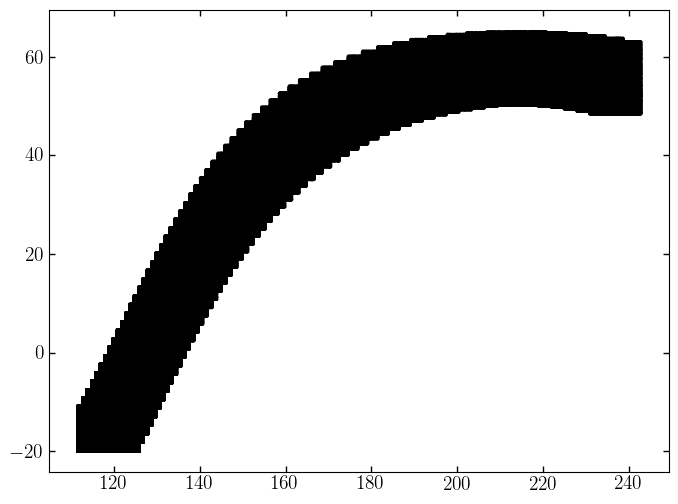

In [135]:
plt.scatter(clean_tbl['raMean'], clean_tbl['decMean'], s=0.001)
plt.show()

In [138]:
c = coord.SkyCoord(ra=clean_tbl['raMean'], dec=clean_tbl['decMean'], unit='deg', frame='icrs')

In [ ]:
c_stream = c.transform_to(gcoord.GD1Koposov10())

In [142]:
clean_tbl['phi1'] = c_stream.phi1.degree
clean_tbl['phi2'] = c_stream.phi2.degree

In [ ]:
ps1_tbl_final = clean_tbl[(clean_tbl['phi1'] > -100) & 
                          (clean_tbl['phi1'] < 20) & 
                          (clean_tbl['phi2'] > -8) & 
                          (clean_tbl['phi2'] < 3.35)]
# ps1_tbl_final.write('/Users/Tavangar/Work/gd1-dr3/data/PS1_data/ps1_tbl_final.fits', overwrite=True)

In [2]:
ps1_tbl = at.Table.read('/Users/Tavangar/Work/gd1-dr3/data/dataset_data/ps1_tbl_final.fits')

In [ ]:
import requests, os
base_url = "https://cdn.gea.esac.esa.int/Gaia/gedr3/cross_match/panstarrs1_best_neighbour/"

strings = [f'{i:04d}' for i in range(1,97)]
filenames = [f'panstarrs1BestNeighbour{string}.csv.gz' for string in strings]

os.makedirs(data_path / 'PS1_data/gaia_ps1_xmatch', exist_ok=True)
for f in filenames:
    out_path = f"gaia_ps1_xmatch/{f}"
    if not os.path.exists(out_path):
        resp = requests.get(base_url + f, stream=True)
        resp.raise_for_status()
        with open(out_path, "wb") as fh:
            for chunk in resp.iter_content(chunk_size=1 << 20):
                fh.write(chunk)
        print("downloaded", f)

downloaded panstarrs1BestNeighbour0000.csv.gz
downloaded panstarrs1BestNeighbour0001.csv.gz
downloaded panstarrs1BestNeighbour0002.csv.gz
downloaded panstarrs1BestNeighbour0003.csv.gz
downloaded panstarrs1BestNeighbour0004.csv.gz
downloaded panstarrs1BestNeighbour0005.csv.gz
downloaded panstarrs1BestNeighbour0006.csv.gz
downloaded panstarrs1BestNeighbour0007.csv.gz
downloaded panstarrs1BestNeighbour0008.csv.gz
downloaded panstarrs1BestNeighbour0009.csv.gz
downloaded panstarrs1BestNeighbour0010.csv.gz
downloaded panstarrs1BestNeighbour0011.csv.gz
downloaded panstarrs1BestNeighbour0012.csv.gz
downloaded panstarrs1BestNeighbour0013.csv.gz
downloaded panstarrs1BestNeighbour0014.csv.gz
downloaded panstarrs1BestNeighbour0015.csv.gz
downloaded panstarrs1BestNeighbour0016.csv.gz
downloaded panstarrs1BestNeighbour0017.csv.gz
downloaded panstarrs1BestNeighbour0018.csv.gz
downloaded panstarrs1BestNeighbour0019.csv.gz
downloaded panstarrs1BestNeighbour0020.csv.gz
downloaded panstarrs1BestNeighbour

In [3]:


# set of your PS1 objIDs — O(1) lookup, much smaller than the full xmatch table
ps1_ids = set(ps1_tbl['objID'].astype('int64'))

cols_needed = ["original_ext_source_id", "source_id"]
id_to_gaia = {}  # only ever holds matched rows, not the full 300M

for f in sorted(glob.glob("gaia_ps1_xmatch/*.csv.gz")):
    # read in sub-chunks so even a single file doesn't fully load at once
    for piece in pd.read_csv(f, comment="#", usecols=cols_needed,
                              dtype={'original_ext_source_id': 'int64', 'source_id': 'int64'},
                              chunksize=2_000_000):
        piece = piece[piece['original_ext_source_id'].isin(ps1_ids)]
        if not piece.empty:
            id_to_gaia.update(
                zip(piece['original_ext_source_id'].to_numpy(),
                    piece['source_id'].to_numpy())
            )
        del piece

    print(f"done {f}: {len(id_to_gaia)} matches so far")
    gc.collect()

/Users/Tavangar/Work/virtual_envs/.stream-env/lib/python3.12/site-packages/pandas/core/computation/expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


done gaia_ps1_xmatch/panstarrs1BestNeighbour0001.csv.gz: 0 matches so far
done gaia_ps1_xmatch/panstarrs1BestNeighbour0002.csv.gz: 0 matches so far
done gaia_ps1_xmatch/panstarrs1BestNeighbour0003.csv.gz: 0 matches so far
done gaia_ps1_xmatch/panstarrs1BestNeighbour0004.csv.gz: 0 matches so far
done gaia_ps1_xmatch/panstarrs1BestNeighbour0005.csv.gz: 0 matches so far
done gaia_ps1_xmatch/panstarrs1BestNeighbour0006.csv.gz: 0 matches so far
done gaia_ps1_xmatch/panstarrs1BestNeighbour0007.csv.gz: 0 matches so far
done gaia_ps1_xmatch/panstarrs1BestNeighbour0008.csv.gz: 0 matches so far
done gaia_ps1_xmatch/panstarrs1BestNeighbour0009.csv.gz: 0 matches so far
done gaia_ps1_xmatch/panstarrs1BestNeighbour0010.csv.gz: 0 matches so far
done gaia_ps1_xmatch/panstarrs1BestNeighbour0011.csv.gz: 0 matches so far
done gaia_ps1_xmatch/panstarrs1BestNeighbour0012.csv.gz: 0 matches so far
done gaia_ps1_xmatch/panstarrs1BestNeighbour0013.csv.gz: 0 matches so far
done gaia_ps1_xmatch/panstarrs1BestNei

In [4]:
gaia_ids = np.array([id_to_gaia.get(oid, -1) for oid in ps1_tbl['objID']], dtype='int64')
mask = gaia_ids == -1

ps1_tbl['gaia_source_id'] = np.ma.masked_array(gaia_ids, mask=mask)

In [5]:
ps1_tbl

objID,raMean,decMean,nDetections,ng,nr,ni,nz,ny,gMeanPSFMag,rMeanPSFMag,iMeanPSFMag,zMeanPSFMag,yMeanPSFMag,gMeanPSFMagErr,rMeanPSFMagErr,iMeanPSFMagErr,zMeanPSFMagErr,yMeanPSFMagErr,gMeanKronMag,rMeanKronMag,iMeanKronMag,zMeanKronMag,yMeanKronMag,gMeanKronMagErr,rMeanKronMagErr,iMeanKronMagErr,zMeanKronMagErr,yMeanKronMagErr,phi1,phi2,gaia_source_id
int64,float64,float64,int16,int16,int16,int16,int16,int16,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,int64
89401205170970392,120.51708840528478,-15.499962543805664,48,4,7,14,10,13,16.248899459838867,15.53950023651123,15.287300109863281,15.158599853515625,15.084199905395508,0.001164000015705824,0.002773999935016036,0.0019099999917671084,0.0020200000144541264,0.002337000099942088,16.310699462890625,15.604999542236328,15.339400291442871,15.222999572753906,15.118499755859375,0.00253499997779727,0.0017960000550374389,0.003897000104188919,0.0027979998849332333,0.008057000115513802,-98.1124622975436,-4.18520798074739,5724424672307363840
94251180116164970,118.01158818509256,-11.454517023161962,51,7,10,8,10,16,18.30430030822754,17.812000274658203,17.600500106811523,17.506999969482422,17.449800491333008,0.009194999933242798,0.009933999739587307,0.006634000223129988,0.009875999763607979,0.007246000226587057,18.393600463867188,17.874300003051758,17.71430015563965,17.61479949951172,17.595800399780273,0.010018999688327312,0.01785700023174286,0.007621000055223703,0.011346000246703625,0.02209099940955639,-95.83093683728059,-0.04959935731627027,3037196710466205184
94251180664479566,118.0664622180098,-11.450712414049582,48,8,7,11,9,13,20.212900161743164,19.496299743652344,19.17609977722168,19.058399200439453,18.8981990814209,0.013782000169157982,0.007683000061661005,0.01919100061058998,0.03372099995613098,0.017395999282598495,20.32979965209961,19.628700256347656,19.30389976501465,19.210100173950195,19.022499084472656,0.026662999764084816,0.017988000065088272,0.023787999525666237,0.028529999777674675,0.03267199918627739,-95.80045301510721,-0.09407021842573543,3037196538669043200
94251180908044575,118.09072142489018,-11.454860383758431,54,10,7,10,15,12,20.066600799560547,19.625,19.46190071105957,19.424400329589844,19.260299682617188,0.02463800087571144,0.01631299965083599,0.01385200023651123,0.016530999913811684,0.05036599934101105,20.043899536132812,19.409799575805664,19.490699768066406,19.517200469970703,19.215299606323242,0.03553500026464462,0.04232500120997429,0.034738000482320786,0.0344650000333786,0.14055900275707245,-95.79200881225574,-0.11668012242791007,3037149981221961856
94251189585328740,118.95852704493778,-11.451390892445653,77,18,10,19,11,19,17.537799835205078,17.178600311279297,17.042800903320312,16.991899490356445,16.964500427246094,0.006585000082850456,0.0029849999118596315,0.003046999918296933,0.003037000074982643,0.003717999905347824,17.61370086669922,17.24959945678711,17.115999221801758,17.092899322509766,17.05470085144043,0.006831000093370676,0.004470000043511391,0.003541999962180853,0.004002000205218792,0.012597999535501003,-95.36003155883716,-0.8493577102855081,3036504224299122688
92061159935442486,115.99353430978319,-13.281562750884303,63,17,9,12,13,12,19.92569923400879,18.685400009155273,18.055400848388672,17.731399536132812,17.521799087524414,0.026064999401569366,0.0030330000445246696,0.003845999948680401,0.0036849998869001865,0.007627000100910664,20.113000869750977,18.76490020751953,18.09510040283203,17.755300521850586,17.564899444580078,0.044293999671936035,0.004403000231832266,0.0059710000641644,0.00889500044286251,0.02141300030052662,-98.40704810586806,0.7168070196440139,3030535349332213120
92061160025611383,116.00255198319822,-13.282534558144398,36,8,8,13,7,0,21.705699920654297,21.113500595092773,20.7726993560791,20.689899444580078,-999.0,0.044263001531362534,0.08858399838209152,0.03782299906015396,0.047961000353097916,-999.0,21.6854000091

In [6]:
ps1_tbl.write('/Users/Tavangar/Work/gd1-dr3/data/PS1_data/ps1_tbl_final.fits', overwrite=True)

## Other Radial Velocities

### APOGEE

Download APOGEE data from allStarLite catalog online

In [ ]:
allstar = at.Table.read('/Users/Tavangar/Work/multipurpose_data/allStarLite-dr17-synspec_rev1.fits')
# allstar_c = coord.SkyCoord(
#     allstar['RA'][np.isfinite(allstar['RA'])], 
#     allstar['DEC'][np.isfinite(allstar['RA'])], 
#     unit=u.deg
# )

### SDSS

In [99]:
# get the WSID and password if not already defined
import getpass
if not os.environ.get('CASJOBS_USERID'):
    os.environ['CASJOBS_USERID'] = 'ktavangar'
if not os.environ.get('CASJOBS_PW'):
    os.environ['CASJOBS_PW'] = 'Sharksinthecc21!m'

from astropy.constants import c as speed_of_light

query = """
SELECT
    s.ra, s.dec, s.class, s.zWarning, s.seguePrimary,
    s.z, s.zErr,
    p.ELODIERVFINAL, p.ELODIERVFINALERR
INTO MyDB.sdss_rv
FROM SpecObjAll AS s
LEFT JOIN sppParams AS p ON s.specObjID = p.SPECOBJID
WHERE
    s.class = 'STAR'
    AND s.zWarning = 0
    AND s.seguePrimary = 1
"""

jobs = mastcasjobs.MastCasJobs(context="SDSSDR17")
results = jobs.submit(query, task_name="sdss_rv")

In [ ]:
sdss_rvs = at.Table.read('/Users/Tavangar/Work/gd1-dr3/data/sdss_rv_ktavangar_downloaded.fit')

In [174]:
# Convert pipeline z to velocity in km/s
c_kms = speed_of_light.to(u.km/u.s)
sdss_rvs['rv'] = sdss_rvs['z'] * c_kms + 7.55 * u.km / u.s # offset from Adrian notebook
sdss_rvs['rv_err'] = sdss_rvs['zErr'] * c_kms
sdss_rvs.write('/Users/Tavangar/Work/gd1-dr3/data/sdss_rvs_all.fits', overwrite=True)

In [ ]:
# Cut to the GD-1 stream track
coords = SkyCoord(ra=sdss_rvs['ra']*u.deg, dec=sdss_rvs['dec']*u.deg)
gd1_coords = coords.transform_to(gcoord.GD1Koposov10)
phi1, phi2 = gd1_coords.phi1.deg.flatten(), gd1_coords.phi2.deg.flatten()
mask = np.abs(phi2) < 2.0
sdss_rvs_stream = sdss_rvs[mask]

mask.sum()

np.int64(11041)

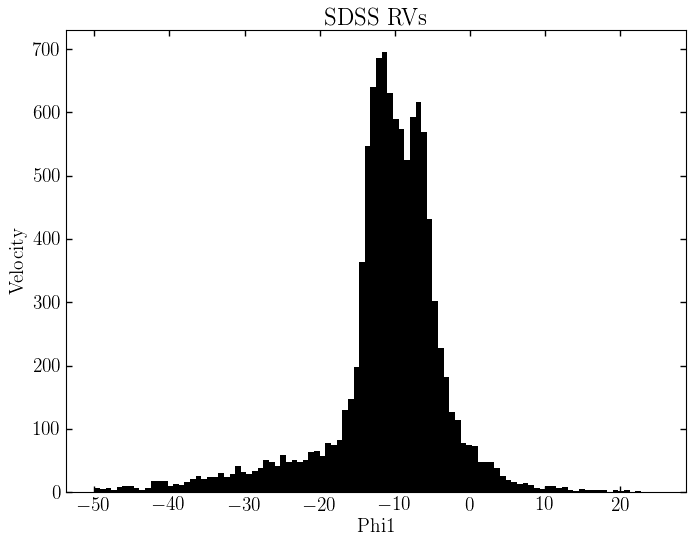

In [121]:
plt.hist(sdss_rvs_stream['v_pipeline'] - sdss_rvs_stream['ELODIERVFINAL'], bins=100, range=[-50,25])
# plt.scatter(phi1[mask], sdss_rvs_stream['ELODIERVFINAL'], alpha=0.2)
plt.xlabel('Phi1')
plt.ylabel('Velocity')
plt.title('SDSS RVs')
plt.show()

### SEGUE

### LAMOST

Downloaded from their website the Stellar Parameter Catalog of A, F, G, and K stars from DR11 v2.0. I took the following columns:
obsid, z, z_err, ps_id, gaia_source_id, ra, dec, feh, feh_err, rv, rv_err, alph_m, alpha_m_err

In [128]:
import pandas as pd    
df = pd.read_csv('/Users/Tavangar/Work/gd1-dr3/data/lamost_rvs.csv')

In [129]:
df # currently all-sky

,obsid,z,z_err,ps_id,gaia_source_id,ra,dec,feh,feh_err,rv,rv_err,alpha_m,alpha_m_err
0,734508151,-0.000144,0.000013,1.157325e+17,4438195560448287744,245.060025,6.441977,-0.526,0.063,-43.24,3.77,-9999.000000,-9999.000000
1,734508153,-0.000237,0.000017,1.158625e+17,4438200542610357760,245.037795,6.550916,-0.601,0.032,-70.94,5.00,0.145232,0.011437
2,734508154,-0.000332,0.000032,1.159625e+17,4438218718911959808,245.046511,6.636005,-0.814,0.124,-99.56,9.70,-9999.000000,-9999.000000
3,734508155,-0.000056,0.000028,1.158324e+17,4438200095933760256,244.997240,6.532827,-0.573,0.111,-16.82,8.44,-9999.000000,-9999.000000
4,734508158,-0.000031,0.000020,1.157124e+17,4438197553312918656,244.932488,6.430082,-0.405,0.066,-9.25,5.98,-9999.000000,-9999.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...
7898019,734508136,-0.000384,0.000022,1.157625e+17,4439499993557642496,245.677722,6.471990,-0.495,0.101,-115.04,6.59,-9999.000000,-9999.000000
7898020,734508137,-0.000115,0.000030,1.159625e+17,4439520918638329856,245.762737,6.640668,0.169,0.144,-34.43,9.04,-9999.000000,-9999.000000
7898021,734508144,-0.000774,0.000026,1.159625e+17,4439518509156676096,245.592838,6.639717,-1.457,0.083,-231.92,7.65,0.381162,0.027511
7898022,734508145,0.000077,0.000011,1.159825e+17,4439510541997329792,245.845893,6.653426,-0.576,0.021,23.08,3.40,0.369131,0.010808


### Hecto-Spec

Get from Adrian

### DESI DR1

In [11]:
desi_query = '''
SELECT 
    mws.source_id AS gaia_sourceid, mws.targetid, p.ra, p.dec, 
    mws.alphafe, mws.alphafe_err, mws.feh, mws.feh_err, 
    mws.vrad, mws.vrad_err, mws.vrad_skew, mws.vrad_kurt, mws.rvs_warn
FROM desi_dr1.mws AS mws
JOIN desi_dr1.photometry AS p ON mws.targetid = p.targetid
WHERE q3c_poly_query(p.ra, p.dec, ARRAY[
    {c[0].ra.degree}, {c[0].dec.degree},
    {c[1].ra.degree}, {c[1].dec.degree},
    {c[2].ra.degree}, {c[2].dec.degree},
    {c[3].ra.degree}, {c[3].dec.degree}
])
'''

In [12]:
job_ids = np.array([])
bin_width=10

desi_data_path = pathlib.Path('../../data/gd1-desi-polygon/').resolve()
desi_data_path.mkdir(exist_ok=True, parents=True)

for i, l in enumerate(np.arange(-100, 20, bin_width)):
    print(l)
    
    fn = desi_data_path / f'gd1_DESI_DR1_{l:.0f}.fits'
    if fn.exists():
        print(f'{fn!s} exists...skipping')
        continue

    corners = gcoord.GD1Koposov10(
        phi1=[l, l, l+bin_width, l+bin_width]*u.deg, 
        phi2=[-10, 5, 5, -10]*u.deg
    )
    corners_icrs = corners.transform_to(coord.ICRS())
    q = desi_query.format(
        c=corners_icrs
    )
    results = qc.query(sql=q, fmt='fits', out=str(fn))
    print(results)

-100
OK
-90
OK
-80
OK
-70
OK
-60
OK
-50
OK
-40
OK
-30
OK
-20
OK
-10
OK
0
OK
10
OK


In [17]:
stream_frame = gcoord.GD1Koposov10()

all_filename = pathlib.Path('/Users/Tavangar/Work/gd1-dr3/data/gd1-desi-all.fits')
if not all_filename.exists():
    arrs = []
    for filename in desi_data_path.glob('*.fits'):
        arrs.append(np.array(fits.getdata(filename)))
    arr = stack_arrays(arrs, asrecarray=True, usemask=False)

    tbl = pyia.GaiaData(arr)

    tbl.data.write(all_filename, overwrite=True)


In [15]:
tbl.data

gaia_sourceid,targetid,ra,dec,alphafe,alphafe_err,feh,feh_err,vrad,vrad_err,vrad_skew,vrad_kurt,rvs_warn
int64,int64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,int64
629859565298864896,39628323176842072,150.5527696254902,22.73358963745677,0.08595631001218207,0.3721864285650205,-3.999996362562056,0.0006772043619548319,192.2110812486708,196.7492512286991,0.7099861057263708,3.852347697303205,13
629859324780565376,39628323176842366,150.5745216622886,22.72603661147878,-0.3687311597769116,0.09843080166139916,-4.000000015676369,0.000556529589973932,-79.86768520011547,107.708167766511,0.8031449320924465,23.96637366417492,13
629908940243019776,39628323176842447,150.5801801937024,22.83771055227588,0.6885175223624367,0.04821545183061442,-3.999994866877388,0.000676096290080146,-376.236900537974,49.89459400747821,-0.6017065619551973,3.145141165717993,8
629912032619496832,39628323172649765,150.4100266199343,22.86755893507941,0.4292519669369799,0.03156347312892353,-1.616410632874639,0.03211748098026172,-35.44129341631937,0.7170112886998442,-0.003105400622636071,3.000563337068104,0
629912689749041792,39628323172650427,150.4540737169076,22.86423424970459,0.3882605352305794,0.4653016560522867,-2.94617629056695,0.6327445188447333,-649.7025265462438,165.0400526572578,2.669413613579746,17.47675063058934,5
629926807307041280,39628328746879345,150.3305057757975,22.984138390442,0.5422685478244142,0.01620627937695585,-3.017738046731815,0.06287117070468967,1499.925999569169,11.44912562598915,-2.13712370134203,5.973696877042238,2
629912616735053568,39628328751071612,150.4788164024784,22.87841590232981,-0.3999999018429647,0.0003974145636805101,-2.571078991537367,0.07015804718854068,1439.781220587139,31.41994347536525,-0.3391921674933317,2.719284064949422,0
629937355746759936,39628334316913097,150.4343672914212,23.1504107728406,-0.3999997491056652,0.000229692919149153,-2.864127458375235,0.1312250628453951,261.0852736341416,72.20918943609009,-0.77191715432582,3.153883505699172,0
629921069230753664,39628328751072638,150.5536537586896,23.04730824440313,-0.2788378133165899,0.1418184254824898,-3.999998674933654,0.0008889734637319503,-179.9838876729794,339.0832017579225,-2.258810772022954,6.750609554408517,12
